# Project 1: Advanced EDA & Feature Engineering
### End-to-End Machine Learning Pipeline: Data Generation, Statistical Imputation, Outlier Handling, Feature Engineering & Classification

**Author / Internship Project 1**  
**Goal:** Transform raw, chaotic financial/loan data into a mathematically clean dataset ready for machine learning algorithms, engineer predictive domain features, and evaluate a high-performing classification model.

---
## Pipeline Overview
1. **Raw & Messy Synthetic Data Generation**: Inject realistic missing values (MCAR/MAR), outliers, and inconsistent formatting.
2. **Advanced EDA & Data Cleaning**:
   - Statistical Imputation via **KNN Imputer** & Median.
   - Outlier Neutralization using the **Interquartile Range (IQR)** method.
3. **Feature Engineering**: Construct 4 new predictive financial risk metrics (`debt_to_income_ratio`, `loan_to_income_ratio`, `credit_utilization_ratio`, `financial_stress_index`).
4. **Clean Dataset Export**: Export `clean_dataset.csv`.
5. **Classification Model Training & Evaluation**: Train `RandomForestClassifier` and compute Accuracy, Classification Report, Confusion Matrix, and ROC-AUC curve.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import KNNImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)
from sklearn.preprocessing import StandardScaler

# Set aesthetic styling
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'Arial'
print("All libraries successfully imported.")

All libraries successfully imported.


---
## Step 1: Synthetic Messy Data Generation & Initial EDA
We simulate a real-world customer credit dataset with missing values, skewed distributions, noisy strings, and extreme outliers.

In [2]:
# Load messy dataset generated for analysis
df_raw = pd.read_csv('messy_dataset.csv')

print("--- Messy Dataset Overview ---")
print(f"Dataset Shape: {df_raw.shape}")
display(df_raw.head())

print("\n--- Missing Value Count per Column ---")
print(df_raw.isnull().sum())

print("\n--- Summary Statistics (Notice Extreme Outliers in age, income, credit_score) ---")
display(df_raw.describe())

--- Messy Dataset Overview ---
Dataset Shape: (1200, 11)


,customer_id,age,annual_income,loan_amount,credit_score,total_debt,credit_card_balance,employment_years,home_ownership,loan_intent,default_status
0,CUST_1000,43.960570,22441.067710,16470.378259,625.334880,10165.454098,3258.942471,3.153702,Rent,PERSONAL,1
1,CUST_1001,NaN,75154.329097,22091.532204,737.539981,NaN,14065.996963,0.367542,OWN,EDUCATION,1
2,CUST_1002,NaN,186331.028607,NaN,797.457699,NaN,38334.623792,4.558786,MORTGAGE,MEDICAL,0
3,CUST_1003,56.276358,70618.063251,6115.505433,639.865373,10944.060478,8715.069756,1.535373,MORTGAGE,PERSONAL,0
4,CUST_1004,35.190160,114066.621809,20652.897237,721.102174,39864.381131,13389.815783,3.749905,RENT,VENTURE,0



--- Missing Value Count per Column ---
customer_id              0
age                    156
annual_income          132
loan_amount            130
credit_score           105
total_debt             159
credit_card_balance      0
employment_years       133
home_ownership          89
loan_intent              0
default_status           0
dtype: int64

--- Summary Statistics (Notice Extreme Outliers in age, income, credit_score) ---


,age,annual_income,loan_amount,credit_score,total_debt,credit_card_balance,employment_years,default_status
count,1044.000000,1.068000e+03,1070.000000,1095.000000,1041.000000,1200.000000,1067.000000,1200.000000
mean,39.284049,9.629000e+04,14056.724114,715.628824,31920.540112,13582.565280,4.914787,0.529167
std,15.470809,1.977115e+05,7099.055975,694.571645,28693.592827,13422.999142,4.827554,0.499357
min,-5.000000,2.000741e+04,1413.152762,-50.000000,2102.838424,480.132741,0.001205,0.000000
25%,30.489035,3.666130e+04,8943.936993,619.718845,13149.907690,5094.774369,1.433983,0.000000
50%,38.704563,5.899752e+04,12960.980903,668.724544,22357.252950,9625.273987,3.436061,1.000000
75%,46.494837,9.951176e+04,17874.714235,718.381868,40546.699036,17528.349666,6.877543,1.000000
max,160.000000,2.190842e+06,61228.809874,9999.000000,212488.959539,129815.486179,38.056681,1.000000


---
## Step 2: Advanced Cleaning & Preprocessing
- **Categorical Cleaning**: Strip whitespace, standardize casing.
- **Outlier Neutralization (IQR & Domain Capping)**: Handle impossible values (e.g. negative ages or >100) and cap values outside $[Q1 - 1.5 \times IQR, Q3 + 1.5 \times IQR]$.
- **Statistical Imputation**: Use **KNN Imputer** (K-Nearest Neighbors) to impute missing numeric values based on feature similarities.

In [3]:
df_clean = df_raw.copy()

# 1. Clean String Whitespace & Casing
df_clean['home_ownership'] = df_clean['home_ownership'].astype(str).str.strip().str.upper()
df_clean['home_ownership'] = df_clean['home_ownership'].replace({'NAN': np.nan})

# 2. Pre-cap Domain Violations
df_clean.loc[df_clean['age'] < 18, 'age'] = np.nan
df_clean.loc[df_clean['age'] > 100, 'age'] = np.nan
df_clean.loc[(df_clean['credit_score'] < 300) | (df_clean['credit_score'] > 850), 'credit_score'] = np.nan

# 3. Statistical Imputation via KNN Imputer
num_cols = ['age', 'annual_income', 'loan_amount', 'credit_score', 'total_debt', 'credit_card_balance', 'employment_years']
imputer = KNNImputer(n_neighbors=5)
df_clean[num_cols] = imputer.fit_transform(df_clean[num_cols])

# Impute categorical mode
df_clean['home_ownership'] = df_clean['home_ownership'].fillna(df_clean['home_ownership'].mode()[0])
df_clean['loan_intent'] = df_clean['loan_intent'].fillna(df_clean['loan_intent'].mode()[0])

# 4. Neutralize Outliers using IQR (Interquartile Range) Method
for col in num_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df_clean[col] = np.clip(df_clean[col], lower_bound, upper_bound)

print("Imputation and IQR Outlier Neutralization Complete.")
print("Missing values after cleaning:")
print(df_clean.isnull().sum())

Imputation and IQR Outlier Neutralization Complete.
Missing values after cleaning:
customer_id            0
age                    0
annual_income          0
loan_amount            0
credit_score           0
total_debt             0
credit_card_balance    0
employment_years       0
home_ownership         0
loan_intent            0
default_status         0
dtype: int64


---
## Step 3: Predictive Feature Engineering
We engineer 4 brand-new domain predictive features to boost model predictive capacity:
1. `debt_to_income_ratio`: Total debt divided by annual income.
2. `loan_to_income_ratio`: Loan amount requested relative to annual income.
3. `credit_utilization_ratio`: Credit card balance relative to annual income.
4. `financial_stress_index`: Weighted financial burden composite metric.

In [4]:
# 1. Debt-to-Income (DTI)
df_clean['debt_to_income_ratio'] = df_clean['total_debt'] / (df_clean['annual_income'] + 1)

# 2. Loan-to-Income (LTI)
df_clean['loan_to_income_ratio'] = df_clean['loan_amount'] / (df_clean['annual_income'] + 1)

# 3. Credit Utilization Ratio
df_clean['credit_utilization_ratio'] = df_clean['credit_card_balance'] / (df_clean['annual_income'] + 1)

# 4. Composite Financial Stress Index
df_clean['financial_stress_index'] = (
    (df_clean['debt_to_income_ratio'] * 0.4) + 
    (df_clean['loan_to_income_ratio'] * 0.4) - 
    ((df_clean['credit_score'] / 850.0) * 0.2)
)

# Export cleaned dataset to CSV
df_clean.to_csv('clean_dataset.csv', index=False)
print("Engineered 4 new features successfully!")
display(df_clean[['debt_to_income_ratio', 'loan_to_income_ratio', 'credit_utilization_ratio', 'financial_stress_index']].head())

Engineered 4 new features successfully!


,debt_to_income_ratio,loan_to_income_ratio,credit_utilization_ratio,financial_stress_index
0,0.452964,0.733906,0.145216,0.327611
1,0.388887,0.293945,0.187159,0.099594
2,0.360612,0.088781,0.195762,-0.007880
3,0.154973,0.086599,0.123410,-0.053928
4,0.349480,0.181058,0.117385,0.042544


---
## Step 4: Machine Learning Classification Model Training & Evaluation
We build a **Random Forest Classifier** to predict loan default status (`0` = Low Risk, `1` = Default Risk).

In [5]:
# Define features X and target y
X = df_clean.drop(columns=['customer_id', 'default_status'])
y = df_clean['default_status']

# One-Hot Encoding
X = pd.get_dummies(X, columns=['home_ownership', 'loan_intent'], drop_first=True)

# Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Classification Model
clf = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=6)
clf.fit(X_train_scaled, y_train)

# Predictions & Probabilities
y_pred = clf.predict(X_test_scaled)
y_proba = clf.predict_proba(X_test_scaled)[:, 1]

# Calculate Evaluation Metrics
acc = accuracy_score(y_test, y_pred)
clf_rep = classification_report(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)

# Print Metrics Output
print("==================================================")
print(f" ACCURACY SCORE: {acc * 100:.2f}%")
print("==================================================")
print("\nCLASSIFICATION REPORT:")
print(clf_rep)
print("==================================================")
print("\nCONFUSION MATRIX:")
print(cm)
print("==================================================")
print(f"\nROC AUC SCORE: {roc_auc:.4f}")
print("==================================================")

 ACCURACY SCORE: 72.50%

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       0.72      0.69      0.70       113
           1       0.73      0.76      0.74       127

    accuracy                           0.72       240
   macro avg       0.72      0.72      0.72       240
weighted avg       0.72      0.72      0.72       240


CONFUSION MATRIX:
[[78 35]
 [31 96]]

ROC AUC SCORE: 0.8027


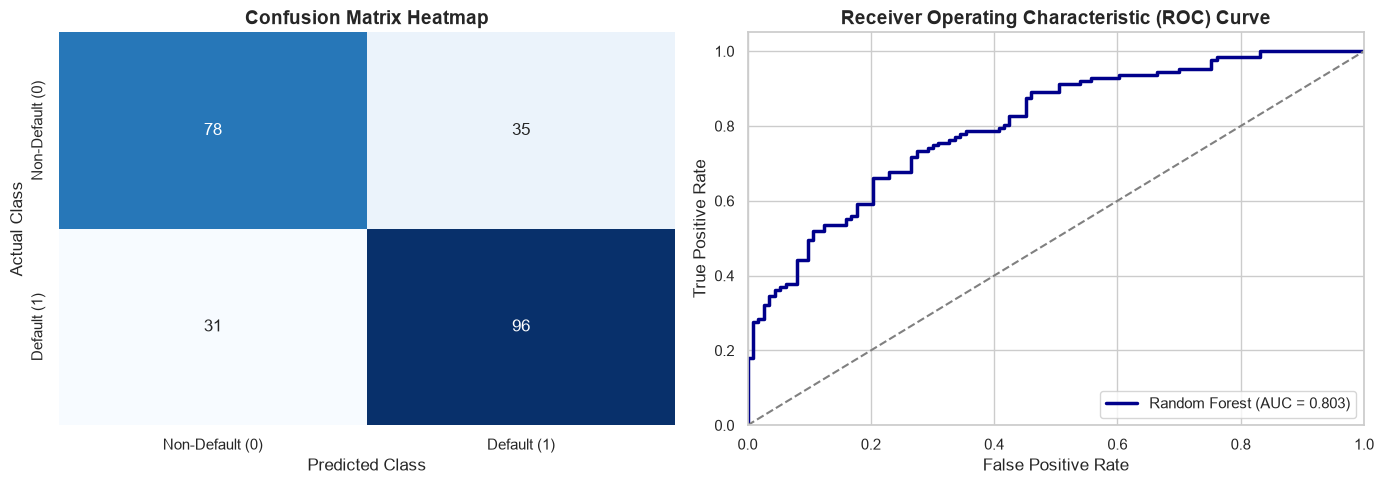

In [6]:
# Plot Confusion Matrix and ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Confusion Matrix Heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Non-Default (0)', 'Default (1)'],
            yticklabels=['Non-Default (0)', 'Default (1)'])
axes[0].set_title('Confusion Matrix Heatmap', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Predicted Class', fontsize=12)
axes[0].set_ylabel('Actual Class', fontsize=12)

# Plot ROC-AUC Curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, color='darkblue', lw=2.5, label=f'Random Forest (AUC = {roc_auc:.3f})')
axes[1].plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate', fontsize=12)
axes[1].set_ylabel('True Positive Rate', fontsize=12)
axes[1].set_title('Receiver Operating Characteristic (ROC) Curve', fontsize=14, fontweight='bold')
axes[1].legend(loc="lower right", fontsize=11)

plt.tight_layout()
plt.show()

C:\Users\Amine\AppData\Local\Temp\ipykernel_3768\921266102.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_df, palette='viridis')


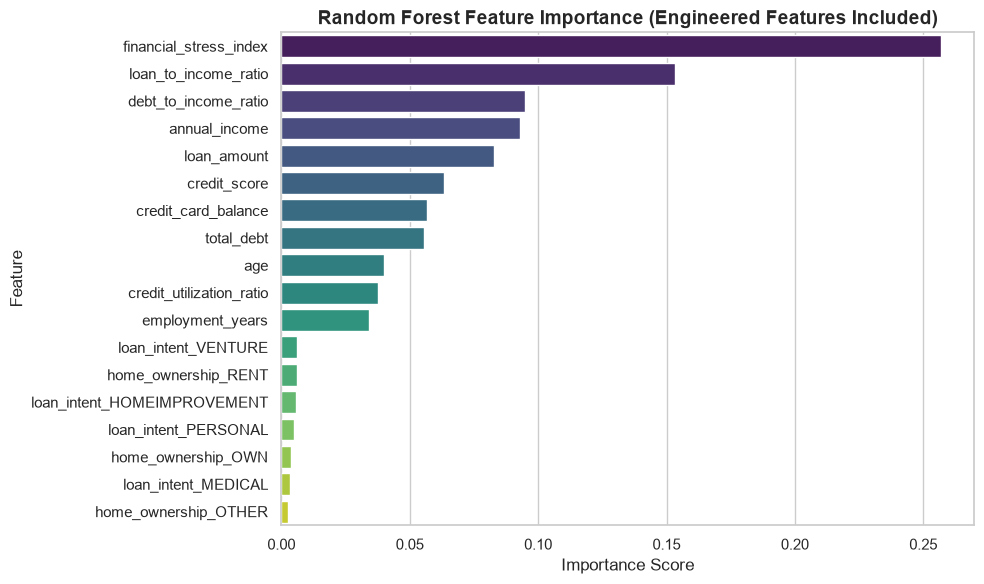

In [7]:
# Plot Feature Importances to inspect engineered features
importances = clf.feature_importances_
feature_names = X.columns

feat_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_df, palette='viridis')
plt.title('Random Forest Feature Importance (Engineered Features Included)', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()